# Frequency-search results explorer

Look at the output of an adversarial frequency search (`freq_search.py`): the
per-`(letter, pattern)` multipliers, the resulting per-word frequencies, and the
greedy strategy analyzed the *same way* as in `strategy_explorer` but under the
adversarial weighting (greedy playing against the adversarial word choices).

Generate a run first with e.g. `python math/freq_search.py 5` (saves to
`math/data/freq_search/len05.csv`); this notebook loads it back.

In [6]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'freq_search.py').exists():
            return c
    raise FileNotFoundError('Could not find freq_search.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import freq_search, strategy

pd.set_option('display.max_rows', 200)

print(f'imported from {math_dir}')

imported from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Load a search result

Loads the saved CSV for this length if present; otherwise runs one inline (which
can be slow for larger lengths).

In [324]:
LENGTH = 10
OBJECTIVE = 'best_opener'      # 'greedy' or 'best_opener' -- which tuned run to explore below

csv_path = freq_search._default_log_path(OBJECTIVE, LENGTH)
if csv_path.exists():
    s = freq_search.FrequencySearch.reconstruct(LENGTH, csv_path, objective=OBJECTIVE)
    print(f'loaded {OBJECTIVE} run: {csv_path.parent.name}/{csv_path.name}')
else:
    print(f'no saved run at {csv_path}\nrunning one inline (may take a while)...')
    s = freq_search.FrequencySearch(LENGTH, objective=OBJECTIVE)
    s.run(verbose=False)

game, f = s.game, s.freq
bo_letter, bo = game.best_opener_misses(f)
print(f'length {LENGTH} [{OBJECTIVE}]: {game.N} words, {s.M} patterns')
print(f'on this tuned distribution -- pure greedy {game.average_misses(f):.4f}   '
      f'best opener {bo:.4f} (via {bo_letter!r})')

loaded best_opener run: best_opener/len10.csv
length 10 [best_opener]: 3359 words, 1089 patterns
on this tuned distribution -- pure greedy 1.1202   best opener 1.1202 (via 's')


## Compare objectives: greedy-tuned vs best-opener-tuned

Load **both** adversarial runs for this length (if present) and score each tuned
distribution with **both** guessers: `greedy_avg` = pure greedy, `best_opener_avg`
= the guesser who picks the best first letter then plays greedy. A distribution
tuned only against *pure greedy* can be escaped by a smarter opener (large `gap`);
one tuned against the *best-opener* guesser leaves little room to improve (small
`gap`). Missing runs are skipped — generate them with `python math/freq_search.py
<LEN>` and `... --best-opener`.

In [325]:
def load_run(objective):
    p = freq_search._default_log_path(objective, LENGTH)
    if not p.exists():
        print(f'  (no {objective!r} run for length {LENGTH} at {p.parent.name}/{p.name})')
        return None
    return freq_search.FrequencySearch.reconstruct(LENGTH, p, objective=objective)

# score each tuned distribution with BOTH guessers
rows = []
for objective in freq_search.OBJECTIVES:
    r = load_run(objective)
    if r is None:
        continue
    gm, fr = r.game, r.freq
    greedy = gm.average_misses(fr)
    bl, bv = gm.best_opener_misses(fr)
    rows.append({'tuned_for': objective,
                 'greedy_avg': greedy, 'greedy_opener': gm.greedy_first_letter(fr),
                 'best_opener_avg': bv, 'best_opener_letter': bl,
                 'gap': greedy - bv})
pd.DataFrame(rows).set_index('tuned_for').round(4)

,greedy_avg,greedy_opener,best_opener_avg,best_opener_letter,gap
tuned_for,,,,,
greedy,1.2146,i,0.8857,e,0.3289
best_opener,1.1202,r,1.1202,s,0.0000


## Multipliers

One row per `(letter, pattern)`; `multiplier` is the tuned weight, `n_words` how
many words carry that pattern.

In [326]:
mult_df = s.multipliers_df()
print(f'{(mult_df.multiplier == 0).sum()} patterns of {len(mult_df)} zeroed; '
      f'{(mult_df.multiplier > 1).sum()} boosted above 1; '
      f'max multiplier {mult_df.multiplier.max():g}')
mult_df.head(200)

147 patterns of 1089 zeroed; 273 boosted above 1; max multiplier 15.875


,letter,pattern,mask,multiplier,n_words
0,a,____a_a__a,592,15.875,2
1,l,__l__l___l,548,8.500,1
2,b,b_____b___,65,8.000,1
3,l,__ll____ll,780,8.000,1
4,k,___k___k__,136,8.000,4
5,i,i___i_i___,81,8.000,3
6,u,_u_u______,10,8.000,2
7,d,___dd_____,24,8.000,1
8,d,___d___d_d,648,7.875,1
9,m,m_m_______,5,7.750,2


In [327]:
mult_df[mult_df['pattern'] == '____s']

,letter,pattern,mask,multiplier,n_words


In [328]:
mult_df.tail(200)

,letter,pattern,mask,multiplier,n_words
889,o,o___o_o___,81,0.125,1
890,o,o__o____o_,265,0.125,1
891,y,y_____y___,65,0.125,1
892,s,s_____s__s,577,0.125,1
893,o,_o__o___o_,274,0.125,1
894,r,r_____r___,65,0.125,15
895,w,__w_w_____,20,0.125,1
896,i,i______i__,129,0.125,35
897,a,_a_a_a____,42,0.125,1
898,o,_o_o_o__o_,298,0.125,1


## Frequencies

One row per word (frequency = product of its pattern multipliers).

In [329]:
freq_df = s.frequencies_df()
print(f'{(freq_df.frequency == 0).sum()} words of {len(freq_df)} at frequency 0 (removed); '
      f'heaviest carry the adversarial weight:')
freq_df.head(200)

328 words of 3359 at frequency 0 (removed); heaviest carry the adversarial weight:


,word,frequency
0,truthfully,32.00
1,compulsory,32.00
2,succumbing,16.00
3,cumulative,16.00
4,gracefully,16.00
5,cappuccino,16.00
6,compulsion,16.00
7,grandchild,16.00
8,childbirth,16.00
9,blacksmith,16.00


In [330]:
freq_df.iloc[354]

word         classmates
frequency           2.0
Name: 354, dtype: object

In [331]:
freq_df['frequency'].sum()

3727.2666015625

In [332]:
x = freq_df[freq_df['word'].str[-3:] == 'ing']
y = freq_df[freq_df['word'].str[-1:] == 's']
x['frequency'].sum() + y['frequency'].sum()

1367.5546875

In [373]:
a = freq_df[freq_df['word'].str[-1:] == 'z']
a['frequency'].sum() / freq_df['frequency'].sum()

0.0

In [334]:
a

,word,frequency
0,truthfully,32.0
1,compulsory,32.0
4,gracefully,16.0
19,abnormally,16.0
25,simplicity,8.0
...,...,...
3244,vocabulary,0.0
3258,obligatory,0.0
3281,incapacity,0.0
3286,admittedly,0.0


In [335]:
y['frequency'].sum() / freq_df['frequency'].sum()

0.2381856048686818

In [336]:
z = freq_df[(freq_df['word'].str[-3:] != 'ing') & (freq_df['word'].str[-1:] != 's')]
z.head(50)

,word,frequency
0,truthfully,32.0
1,compulsory,32.0
3,cumulative,16.0
4,gracefully,16.0
5,cappuccino,16.0
6,compulsion,16.0
7,grandchild,16.0
8,childbirth,16.0
9,blacksmith,16.0
10,campground,16.0


In [337]:
(z['frequency'].sum()) / freq_df['frequency'].sum()

0.633094480838395

In [338]:
len(freq_df[freq_df['frequency'] > 0])

3031

In [339]:
len(x) + len(y)

1267

In [340]:
freq_df.tail(200)

,word,frequency
3159,worldviews,0.0
3160,precursors,0.0
3161,beginnings,0.0
3162,indication,0.0
3163,operations,0.0
3164,disordered,0.0
3165,deficiency,0.0
3166,admissions,0.0
3167,overriding,0.0
3168,diphtheria,0.0


## Uniform baseline + the two guessers on the tuned distribution

Each cell compares three lenses:

- **uniform** — every word equally likely (`freq=None`), pure greedy — the
  "normal game" baseline (the original `strategy_explorer` view);
- **pure greedy** — on the tuned distribution `f`, opens with its highest
  combined-frequency letter (`go`);
- **best opener** — on `f`, forces the single best first letter (`bo_letter`).

The greedy↔best-opener gap on `f` is exactly what the `best_opener` search targets.

uniform     : avg 0.6969  (opens 'e')
pure greedy : avg 1.1202  (opens 'r')
best opener : avg 1.1202  (opens 's')


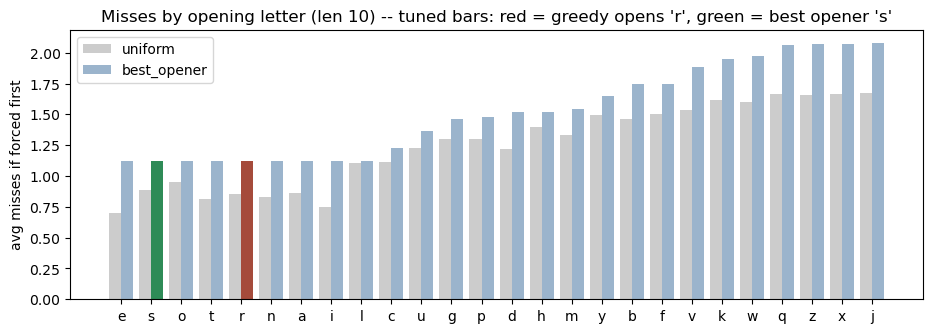

,e,s,o,t,r,n,a,i,l,c,...,y,b,f,v,k,w,q,z,x,j
uniform,0.696934,0.890146,0.951176,0.817208,0.852635,0.833581,0.86365,0.750223,1.105984,1.111640,...,1.491218,1.465019,1.504019,1.535576,1.620125,1.597202,1.666270,1.655255,1.665674,1.676689
best_opener,1.120233,1.120233,1.120234,1.120235,1.120236,1.120239,1.12030,1.120759,1.125533,1.224769,...,1.651696,1.748810,1.749478,1.887815,1.944911,1.969772,2.061537,2.070824,2.073144,2.081760


In [341]:
# the three lenses: uniform baseline, then the two guessers on the tuned distribution
go = game.greedy_first_letter(f)                 # greedy's opener on f
print(f'uniform     : avg {game.average_misses(None):.4f}  (opens {game.greedy_first_letter(None)!r})')
print(f'pure greedy : avg {game.average_misses(f):.4f}  (opens {go!r})')
print(f'best opener : avg {bo:.4f}  (opens {bo_letter!r})')

# Mode B -- misses if each letter is forced first: uniform vs the tuned distribution;
# the tuned bars mark greedy's opener (red) and the best opener (green)
mbu = pd.Series(game.misses_by_starting_letter(None))
mba = pd.Series(game.misses_by_starting_letter(f))
order = list(mba.sort_values().index)
x = np.arange(len(order)); w = 0.4
adv_colors = ['#9bb4cc'] * len(order)
adv_colors[order.index(go)] = '#a54b3b'          # red = greedy opens here
adv_colors[order.index(bo_letter)] = '#2e8b57'   # green = best opener
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - w / 2, mbu[order].values, w, label='uniform', color='#cccccc')
ax.bar(x + w / 2, mba[order].values, w, label=OBJECTIVE, color=adv_colors)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('avg misses if forced first'); ax.legend()
ax.set_title(f'Misses by opening letter (len {LENGTH}) -- tuned bars: '
             f'red = greedy opens {go!r}, green = best opener {bo_letter!r}')
plt.show()
pd.DataFrame({'uniform': mbu[order], OBJECTIVE: mba[order]}).T

## Per-word difficulty: uniform vs greedy vs best opener

All three lenses, frequency-weighted (uniform weights each word equally; the two
tuned lenses weight by `f`; each normalized to a share of total weight).

weighted avg misses -- uniform 0.6969   pure greedy 1.1202   best opener 1.1202


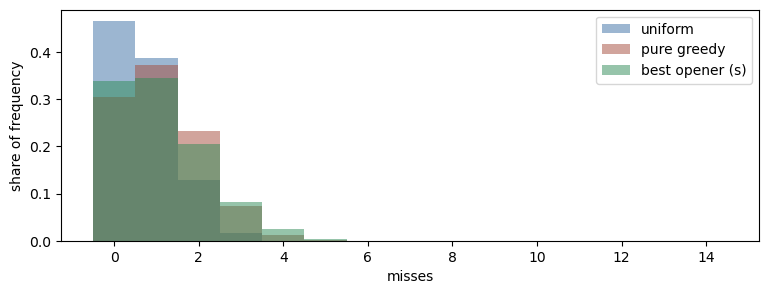

hardest words (pure greedy) under this distribution:


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,inventions,0.0,0,14,14
1,intentions,0.0,0,14,14
2,regulatory,0.0,2,13,3
3,suspicious,0.0,1,13,12
4,regulators,0.0,1,12,1
5,suspicions,0.0,1,12,11
6,ionization,0.0,1,12,7
7,invitation,0.0,1,12,12
8,antagonist,0.0,1,11,1
9,enthusiast,0.0,0,11,9


In [342]:
upm = game.per_word_misses(None)                 # uniform baseline (pure greedy)
gpm = game.per_word_misses(f)                    # pure greedy on the tuned distribution
bpm = game.per_word_misses(f, opener=bo_letter)  # best opener on the tuned distribution
words = pd.DataFrame({'word': game.words, 'freq': f,
                      'misses_uniform':     upm.astype(int),
                      'misses_greedy':      gpm.astype(int),
                      'misses_best_opener': bpm.astype(int)})

print(f'weighted avg misses -- uniform {game.average_misses(None):.4f}   '
      f'pure greedy {game.average_misses(f):.4f}   best opener {bo:.4f}')

bins = range(0, int(max(upm.max(), gpm.max(), bpm.max())) + 2)
fig, ax = plt.subplots(figsize=(9, 3))
for pwm, wt, name, color in [(upm, None, 'uniform',                    '#3b6ea5'),
                             (gpm, f,    'pure greedy',                '#a54b3b'),
                             (bpm, f,    f'best opener ({bo_letter})', '#2e8b57')]:
    ax.hist(pwm, bins=bins, weights=wt, density=True,
            alpha=0.5, label=name, color=color, align='left')
ax.set_xlabel('misses'); ax.set_ylabel('share of frequency'); ax.legend()
plt.show()

print('hardest words (pure greedy) under this distribution:')
words.sort_values('misses_greedy', ascending=False).head(15).reset_index(drop=True)

In [343]:
# The adversary zeros out many words (freq 0) -- those don't count toward its
# average. Hardest words it actually KEEPS (nonzero frequency), with both guessers:
kept = words[words.freq > 0]
print(f'{len(kept)} of {len(words)} words kept (nonzero frequency)')
kept.sort_values('misses_best_opener', ascending=False).head(15).reset_index(drop=True)

3031 of 3359 words kept (nonzero frequency)


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,unexpected,2.0000,0,3,5
1,undetected,0.5000,0,3,5
2,tumbleweed,4.0000,0,2,5
3,uneventful,2.0000,1,2,5
4,vehemently,0.5000,0,2,5
5,excellence,2.0000,0,2,5
6,ineligible,2.0000,0,2,5
7,dependence,1.0000,0,4,5
8,excellency,2.0000,0,2,5
9,lengthened,0.2500,0,2,5


## Trace a word: uniform vs greedy vs best opener

The guess sequence for one word under each lens (`+` = hit, `-` = miss). On the
tuned distribution greedy opens with `go` and the best-opener guesser with
`bo_letter`; the uniform lens is the normal-game baseline.

In [344]:
# hardest word (pure greedy) the adversary actually KEEPS; or set WORD = 'bench'
nz = np.flatnonzero(f > 0)
WORD = game.words[nz[gpm[nz].argmax()]]
print(WORD)
for name, fr, kw in [('uniform', None, {}),
                     (f'greedy (opens {go})',      f, {}),
                     (f'best opener (opens {bo_letter})', f, {'opener': bo_letter})]:
    hits = game.trace(WORD, fr, **kw)
    seq = '  '.join(f'{l}{"+" if h else "-"}' for l, h in hits)
    print(f'{name:>26}  ({sum(1 for _, h in hits if not h)} misses):  {seq}')

cheesecake
                   uniform  (0 misses):  e+  a+  c+  h+  k+  s+
          greedy (opens r)  (5 misses):  r-  i-  l-  t-  n-  e+  a+  c+  h+  k+  s+
     best opener (opens s)  (0 misses):  s+  e+  a+  c+  h+  k+
